# Basic Imports and Cleaning

In [104]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [105]:
df = pd.read_csv("data/potential-talents - Aspiring human resources - seeking human resources.csv")

In [106]:
df.head(25)

,id,job_title,location,connection,fit
0,1,2019 C.T. Bauer College of Business Graduate (...,"Houston, Texas",85,NaN
1,2,Native English Teacher at EPIK (English Progra...,Kanada,500+,NaN
2,3,Aspiring Human Resources Professional,"Raleigh-Durham, North Carolina Area",44,NaN
3,4,People Development Coordinator at Ryan,"Denton, Texas",500+,NaN
4,5,Advisory Board Member at Celal Bayar University,"İzmir, Türkiye",500+,NaN
5,6,Aspiring Human Resources Specialist,Greater New York City Area,1,NaN
6,7,Student at Humber College and Aspiring Human R...,Kanada,61,NaN
7,8,HR Senior Specialist,San Francisco Bay Area,500+,NaN
8,9,Student at Humber College and Aspiring Human R...,Kanada,61,NaN
9,10,Seeking Human Resources HRIS and Generalist Po...,Greater Philadelphia Area,500+,NaN


In [107]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 104 entries, 0 to 103
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id          104 non-null    int64  
 1   job_title   104 non-null    str    
 2   location    104 non-null    str    
 3   connection  104 non-null    str    
 4   fit         0 non-null      float64
dtypes: float64(1), int64(1), str(3)
memory usage: 4.2 KB


There are no null values aside from in fit, which we will be filling up with our calculated fit score.

### removing duplicates

In [108]:
#checking for duplicates
df.duplicated(subset=['job_title', 'location', 'connection']).sum()

np.int64(51)

In [109]:
#examining duplicates
df[df.duplicated(subset=['job_title', 'location', 'connection'])].sort_values(by='job_title')

,id,job_title,location,connection,fit
56,57,2019 C.T. Bauer College of Business Graduate (...,"Houston, Texas",85,NaN
13,14,2019 C.T. Bauer College of Business Graduate (...,"Houston, Texas",85,NaN
14,15,2019 C.T. Bauer College of Business Graduate (...,"Houston, Texas",85,NaN
30,31,2019 C.T. Bauer College of Business Graduate (...,"Houston, Texas",85,NaN
43,44,2019 C.T. Bauer College of Business Graduate (...,"Houston, Texas",85,NaN
18,19,2019 C.T. Bauer College of Business Graduate (...,"Houston, Texas",85,NaN
34,35,Advisory Board Member at Celal Bayar University,"İzmir, Türkiye",500+,NaN
47,48,Advisory Board Member at Celal Bayar University,"İzmir, Türkiye",500+,NaN
22,23,Advisory Board Member at Celal Bayar University,"İzmir, Türkiye",500+,NaN
28,29,Aspiring Human Resources Management student se...,"Houston, Texas Area",500+,NaN


In [110]:
#removing duplicates
df = df.drop_duplicates(subset=['job_title', 'location', 'connection']).reset_index(drop=True)

In [111]:
df.head(25)

,id,job_title,location,connection,fit
0,1,2019 C.T. Bauer College of Business Graduate (...,"Houston, Texas",85,NaN
1,2,Native English Teacher at EPIK (English Progra...,Kanada,500+,NaN
2,3,Aspiring Human Resources Professional,"Raleigh-Durham, North Carolina Area",44,NaN
3,4,People Development Coordinator at Ryan,"Denton, Texas",500+,NaN
4,5,Advisory Board Member at Celal Bayar University,"İzmir, Türkiye",500+,NaN
5,6,Aspiring Human Resources Specialist,Greater New York City Area,1,NaN
6,7,Student at Humber College and Aspiring Human R...,Kanada,61,NaN
7,8,HR Senior Specialist,San Francisco Bay Area,500+,NaN
8,10,Seeking Human Resources HRIS and Generalist Po...,Greater Philadelphia Area,500+,NaN
9,11,Student at Chapman University,"Lake Forest, California",2,NaN


In [112]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53 entries, 0 to 52
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id          53 non-null     int64  
 1   job_title   53 non-null     str    
 2   location    53 non-null     str    
 3   connection  53 non-null     str    
 4   fit         0 non-null      float64
dtypes: float64(1), int64(1), str(3)
memory usage: 2.2 KB


Now that we've dropped duplicates that has cut the data set nearly in half. Next it's time to clean up the job titles to be consistent and the connections to be numeric. Let's check location for consistency as well.

### Data Transformation
cleaning up data types and job title consistency

In [113]:
df['location'].value_counts()

location
Houston, Texas Area                    4
Raleigh-Durham, North Carolina Area    3
Greater New York City Area             3
Kanada                                 2
Greater Philadelphia Area              2
Austin, Texas Area                     2
Amerika Birleşik Devletleri            2
Greater Atlanta Area                   2
Houston, Texas                         1
Denton, Texas                          1
İzmir, Türkiye                         1
San Francisco Bay Area                 1
Lake Forest, California                1
Atlanta, Georgia                       1
Chicago, Illinois                      1
Jackson, Mississippi Area              1
Greater Grand Rapids, Michigan Area    1
Virginia Beach, Virginia               1
Monroe, Louisiana Area                 1
Greater Boston Area                    1
San Jose, California                   1
New York, New York                     1
Dallas/Fort Worth Area                 1
Baton Rouge, Louisiana Area            1
Myrtle 

In [114]:
#removing the + from the connection column
df['connection'] = df['connection'].str.replace('+', '', regex=False)

In [115]:
df.head(25)

,id,job_title,location,connection,fit
0,1,2019 C.T. Bauer College of Business Graduate (...,"Houston, Texas",85,NaN
1,2,Native English Teacher at EPIK (English Progra...,Kanada,500,NaN
2,3,Aspiring Human Resources Professional,"Raleigh-Durham, North Carolina Area",44,NaN
3,4,People Development Coordinator at Ryan,"Denton, Texas",500,NaN
4,5,Advisory Board Member at Celal Bayar University,"İzmir, Türkiye",500,NaN
5,6,Aspiring Human Resources Specialist,Greater New York City Area,1,NaN
6,7,Student at Humber College and Aspiring Human R...,Kanada,61,NaN
7,8,HR Senior Specialist,San Francisco Bay Area,500,NaN
8,10,Seeking Human Resources HRIS and Generalist Po...,Greater Philadelphia Area,500,NaN
9,11,Student at Chapman University,"Lake Forest, California",2,NaN


In [116]:
#Making connection numeric
df['connection'] = df['connection'].astype(int)

In [117]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53 entries, 0 to 52
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id          53 non-null     int64  
 1   job_title   53 non-null     str    
 2   location    53 non-null     str    
 3   connection  53 non-null     int64  
 4   fit         0 non-null      float64
dtypes: float64(1), int64(2), str(2)
memory usage: 2.2 KB


In [118]:
df['job_title'].value_counts()

job_title
Aspiring Human Resources Professional                                                                                    2
2019 C.T. Bauer College of Business Graduate (Magna Cum Laude) and aspiring Human Resources professional                 1
Native English Teacher at EPIK (English Program in Korea)                                                                1
People Development Coordinator at Ryan                                                                                   1
Advisory Board Member at Celal Bayar University                                                                          1
Aspiring Human Resources Specialist                                                                                      1
Student at Humber College and Aspiring Human Resources Generalist                                                        1
HR Senior Specialist                                                                                                     1
Seekin

In [119]:
df['job_title'] = df['job_title'].str.replace(r'\bHR\b', 'Human Resources', regex=True)
df['job_title'].value_counts()

job_title
Aspiring Human Resources Professional                                                                                    2
2019 C.T. Bauer College of Business Graduate (Magna Cum Laude) and aspiring Human Resources professional                 1
Native English Teacher at EPIK (English Program in Korea)                                                                1
People Development Coordinator at Ryan                                                                                   1
Advisory Board Member at Celal Bayar University                                                                          1
Aspiring Human Resources Specialist                                                                                      1
Student at Humber College and Aspiring Human Resources Generalist                                                        1
Human Resources Senior Specialist                                                                                        1
Seekin

I do see this one that is obviously a business looking for candidates. Since this is not what the business is looking for I will remove it

In [120]:
df.head(53)

,id,job_title,location,connection,fit
0,1,2019 C.T. Bauer College of Business Graduate (...,"Houston, Texas",85,NaN
1,2,Native English Teacher at EPIK (English Progra...,Kanada,500,NaN
2,3,Aspiring Human Resources Professional,"Raleigh-Durham, North Carolina Area",44,NaN
3,4,People Development Coordinator at Ryan,"Denton, Texas",500,NaN
4,5,Advisory Board Member at Celal Bayar University,"İzmir, Türkiye",500,NaN
5,6,Aspiring Human Resources Specialist,Greater New York City Area,1,NaN
6,7,Student at Humber College and Aspiring Human R...,Kanada,61,NaN
7,8,Human Resources Senior Specialist,San Francisco Bay Area,500,NaN
8,10,Seeking Human Resources HRIS and Generalist Po...,Greater Philadelphia Area,500,NaN
9,11,Student at Chapman University,"Lake Forest, California",2,NaN


In [121]:
#dropping nortia staffing advertisement at index 23
df = df.drop(23).reset_index(drop=True)

In [122]:
df.head(52)

,id,job_title,location,connection,fit
0,1,2019 C.T. Bauer College of Business Graduate (...,"Houston, Texas",85,NaN
1,2,Native English Teacher at EPIK (English Progra...,Kanada,500,NaN
2,3,Aspiring Human Resources Professional,"Raleigh-Durham, North Carolina Area",44,NaN
3,4,People Development Coordinator at Ryan,"Denton, Texas",500,NaN
4,5,Advisory Board Member at Celal Bayar University,"İzmir, Türkiye",500,NaN
5,6,Aspiring Human Resources Specialist,Greater New York City Area,1,NaN
6,7,Student at Humber College and Aspiring Human R...,Kanada,61,NaN
7,8,Human Resources Senior Specialist,San Francisco Bay Area,500,NaN
8,10,Seeking Human Resources HRIS and Generalist Po...,Greater Philadelphia Area,500,NaN
9,11,Student at Chapman University,"Lake Forest, California",2,NaN


In [123]:
#there appear to be some extra spaces in some of these.
df['job_title'] = df['job_title'].str.replace('  ', ' ', regex=True)

In [124]:
#checking how many columns contain our basic keywords.
df['job_title'].str.contains('human resources', case=False, na=False).sum()

np.int64(33)

In [125]:
df['job_title'].str.contains('aspiring human resources', case=False, na=False).sum()

np.int64(13)

In [126]:
df['job_title'].str.contains('seeking human resources', case=False, na=False).sum()

np.int64(4)

In [127]:
#looking back at the data there are a couple of people who would potentially be missed due to wording
df['job_title'] = df['job_title'].str.replace("seeking a position in Human Resources", "seeking human resources position", regex=True)
df['job_title'] = df['job_title'].str.replace("Seeking an Entry-Level Human Resources Position", "seeking human resources position", regex=True)

In [128]:
df['job_title'].str.contains('seeking human resources', case=False, na=False).sum()

np.int64(6)

## additional EDA

In [129]:
df["connection"].describe()

count     52.000000
mean     236.942308
std      216.124366
min        1.000000
25%       43.000000
50%      129.000000
75%      500.000000
max      500.000000
Name: connection, dtype: float64

(array([17.,  8.,  1.,  2.,  1.,  1.,  1.,  1.,  2., 18.]),
 array([  1. ,  50.9, 100.8, 150.7, 200.6, 250.5, 300.4, 350.3, 400.2,
        450.1, 500. ]),
 <BarContainer object of 10 artists>)

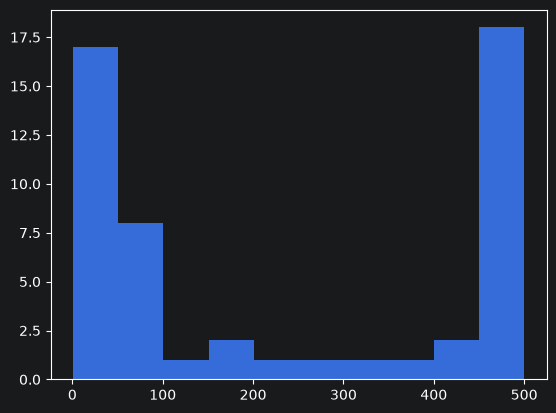

In [130]:
plt.hist(df['connection'])

# Model

In [131]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import MinMaxScaler

In [132]:
#initial ranking of candidates based on title and number of connections
target_phrases = ["aspiring human resources", "seeking human resources"]
vectorizer = TfidfVectorizer(stop_words='english')
job_titles = df["job_title"]
tfidf_matrix = vectorizer.fit_transform(job_titles)
target_matrix = vectorizer.transform(target_phrases)
similarity_scores = cosine_similarity(tfidf_matrix, target_matrix).max(axis=1)

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_connections = scaler.fit_transform(df[['connection']]).flatten()

df["fit"] = (similarity_scores * 0.7) + (scaled_connections * .3)

In [133]:
df.sort_values(by='fit', ascending=False)

,id,job_title,location,connection,fit
13,28,Seeking Human Resources Opportunities,"Chicago, Illinois",390,0.712592
12,27,Aspiring Human Resources Management student se...,"Houston, Texas Area",500,0.629427
8,10,Seeking Human Resources HRIS and Generalist Po...,Greater Philadelphia Area,500,0.608851
44,97,Aspiring Human Resources Professional,"Kokomo, Indiana Area",71,0.572605
2,3,Aspiring Human Resources Professional,"Raleigh-Durham, North Carolina Area",44,0.556373
41,94,Seeking Human Resources Opportunities. Open to...,Amerika Birleşik Devletleri,415,0.513460
46,99,Seeking Human Resources Position,"Las Vegas, Nevada Area",48,0.506981
5,6,Aspiring Human Resources Specialist,Greater New York City Area,1,0.474531
7,8,Human Resources Senior Specialist,San Francisco Bay Area,500,0.470668
25,78,Human Resources Generalist at Schwan's,Amerika Birleşik Devletleri,500,0.465042


In [134]:
def talent_ranker(starred=None, alpha=0.5):
    starred = starred or []
    base_fit = df['fit']

    if len(starred) > 0:
      tfidf_matrix = vectorizer.fit_transform(
          df["job_title"])
      starred_vectors = tfidf_matrix[starred]
      centroid = np.asarray(starred_vectors.mean(axis=0))
      sim_scores = cosine_similarity(tfidf_matrix, centroid).flatten()
      df["starred_fit"] = ((1 - alpha) * base_fit) + (alpha * sim_scores)
    else:
      df["starred_fit"] = base_fit

    df["starred_fit"] = df["starred_fit"].clip(0.0, 1.0)

    # Sort DataFrame descending by fit score
    ranked_df = df.sort_values(by="starred_fit", ascending=False)

    return ranked_df

In [135]:
df_star_rank = talent_ranker(starred = [23, 41], alpha=0.5)
df_star_rank

,id,job_title,location,connection,fit,starred_fit
41,94,Seeking Human Resources Opportunities. Open to...,Amerika Birleşik Devletleri,415,0.513460,0.617109
13,28,Seeking Human Resources Opportunities,"Chicago, Illinois",390,0.712592,0.572452
23,76,Aspiring Human Resources Professional | Passio...,"New York, New York",212,0.307149,0.513954
44,97,Aspiring Human Resources Professional,"Kokomo, Indiana Area",71,0.572605,0.443971
2,3,Aspiring Human Resources Professional,"Raleigh-Durham, North Carolina Area",44,0.556373,0.435855
12,27,Aspiring Human Resources Management student se...,"Houston, Texas Area",500,0.629427,0.415191
8,10,Seeking Human Resources HRIS and Generalist Po...,Greater Philadelphia Area,500,0.608851,0.378052
46,99,Seeking Human Resources Position,"Las Vegas, Nevada Area",48,0.506981,0.367614
21,73,"Aspiring Human Resources Manager, seeking inte...","Houston, Texas Area",7,0.447753,0.361815
5,6,Aspiring Human Resources Specialist,Greater New York City Area,1,0.474531,0.333419


How can we filter out candidates which in the first place should not be in this list?
    One way would be to clean the data to exclude any candidate that does not contain the words "human resources" in their title. This could be done manually, or it could be built into the code so that it can be run on different sets of data. This model will naturally put inappropriate candidates at the bottom of the list, but will not remove them entirely.

Can we determine a cut-off point that would work for other roles without losing high potential candidates?
    It's likely that you could choose a score below which you would not consider candidates. Looking at this model .30 appears to be a good threshold below which the candidates are not a great fit. The model would have to be tested on multiple different datasets for a different roles to determine if .30 can be used as a universal cutoff.

Do you have any ideas that we should explore so that we can even automate this procedure to prevent human bias?
    Viewing the candidates without personally identifiable information is a good start. It's the same reason why APA formatting uses initials instead of names and many orchestras do blind auditions which the musician is behind a curtain; some orchestras go so far as to include carpet so that assumptions cannot be drawn from the sound of a person's shoes or their gait. Names offer the opportunity for bias. Letting the model rank people for you is a good next step as it applies rules consistently to all candidates. It is important to remember that models can contain bias. For instance, I have built this one to prefer candidates with more LinkedIn connections which might exclude perfectly good candidates who are early in their career; everyone has to start somewhere.